In [1]:
# Core Langgraph Frameworks
!pip install langgraph
!pip install langchain-openai
!pip install langchain
!pip install pydantic
!pip install grandalf
!pip install langchain-community
!pip install duckduckgo-search
!pip install -U ddgs

In [2]:
# Import all dependencies

import os
from typing import Annotated, Literal, TypedDict
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import END, StateGraph, START
from langgraph.graph.message import add_messages
from IPython.display import display,Image
from pydantic import BaseModel, Field

/tmp/ipykernel_21238/1547169680.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


In [3]:
# Set up OpenAI API Key
import os
from google.colab import userdata
os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_APIKEY')

In [4]:
# ==========================================
# Step 1: Initialize LLM
# ==========================================
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.2)


In [5]:
# ==========================================
# Step 2: Initialize Internet Tool
# ==========================================
search_tool = DuckDuckGoSearchRun()

In [6]:
# ==========================================
# Step 3: Setup Shared State
# ==========================================

class AgentState(TypedDict):
    user_query: str
    messages: Annotated[list[BaseMessage], add_messages]
    specs_data: str
    reviews_data: str
    price_data: str
    final_recommendation: str
    selected_agents: list[str]


In [7]:
# ==========================================
# Step 4: Setup schema for Supervisor routing decision
# ==========================================
class SupervisorRouting(BaseModel):
    selected_agents: list[Literal["specification_agent", "review_agent", "price_agent"]] = Field(
        description="List of worker agents needed based on user query requirements."
    )

In [8]:
# ==========================================
# Step 5: Setup Supervior Agent
# ==========================================

def supervisor_agent(state: AgentState) -> dict:
    """Routes initial request to LLM to take decision."""
    structured_llm = llm.with_structured_output(SupervisorRouting)
    system_prompt = (
        "You are a Supervisor Routing Agent. Analyze the user query and decide which worker agents to invoke:\n"
        "- 'specification_agent': If hardware specs, features, display, performance comparison is needed.\n"
        "- 'review_agent': If critical reviews, pros/cons, or sentiment analysis is needed.\n"
        "- 'price_agent': If pricing, cost, deals, or value-for-money analysis is needed."
    )

    decision: SupervisorRouting = structured_llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=state["user_query"])
    ])

    print("\n")
    print("  " + "="*70)
    print(f"\ninside supervisor_agent --> decision.selected_agents: {decision.selected_agents}")
    print("  " + "="*70)
    print("\n")
    return {"selected_agents": decision.selected_agents}

In [9]:
# =======================================================
# Step 6: Setup Router Function for Conditional Edges
# =======================================================

def route_to_workers(state: AgentState) -> list[str]:
    """Returns the list of nodes to run in parallel based on supervisor's decision."""
    print("\n")
    print("  " + "="*70)
    print(f"\ninside route_to_workers --> state[selected_agents]: {state["selected_agents"]}")
    print("  " + "="*70)
    print("\n")
    return state["selected_agents"]

In [10]:
# ==========================================
# Step 7: Setup Specification Agent
# ==========================================

def specification_agent(state: AgentState) -> dict:
    prompt = SystemMessage(
        content=f"You are a Hardware Specifications Specialist. Only give "
        "specifications and nothing else."
        "Do not show any Review and Price details "
    )
    # Uses internal LLM knowledge base for hardware specs
    search_results = search_tool.invoke("iPhone 17 vs Samsung Galaxy S26 specifications")
    response = llm.invoke([
        prompt,
        HumanMessage(content=f"Query: {state['user_query']}\n\nSearch Results: {search_results}")
    ])
    specification_response = response.content
    print("\n")
    print("  " + "="*70)
    print(f"inside specification_agent --> specs_data: {specification_response}")
    print("  " + "="*70)
    print("\n")
    return {"specs_data": specification_response}

In [11]:
# ==========================================
# Step 8: Setup Review Agent
# ==========================================

def review_agent(state: AgentState) -> dict:
    prompt = SystemMessage(
        content="You are a Review Aggregator. Analyze reviews "
        "for the iPhone 17 and Samsung Galaxy S26 and nothing else ."
        "Donot show any Specification or Price Details "
    )
    search_results = search_tool.invoke("iPhone 17 vs Samsung Galaxy S26 reviews")
    response = llm.invoke([
        prompt,
        HumanMessage(content=f"Query: {state['user_query']}\n\nSearch Results: {search_results}")
    ])
    review_response = response.content
    print("\n")
    print("  " + "="*70)
    print(f"inside review_agent --> reviews_data: {review_response}")
    print("  " + "="*70)
    print("\n")
    return {"reviews_data": review_response}



In [12]:
# ==========================================
# Step 9: Setup Price Agent
# ==========================================

def price_agent(state: AgentState) -> dict:
    prompt = SystemMessage(
        content="You are a Consumer Market Pricing Analyst. Gather accurate current prices "
        "tradeoffs between the iPhone 17 and Samsung Galaxy S26 across different storage tiers. "
        "Donot show any specification or reviews "
    )
    search_results = search_tool.invoke("iPhone 17 vs Samsung Galaxy S26 price ")
    response = llm.invoke([
        prompt,
        HumanMessage(content=f"Query: {state['user_query']}\n\nSearch Results: {search_results}")
    ])
    price_response = response.content
    print("\n")
    print("  " + "="*70)
    print(f"inside price_agent --> price_data: {price_response}")
    print("  " + "="*70)
    print("\n")
    return {"price_data": price_response}

In [13]:
# ==========================================
# Step 10: Setup synthesizer Agent
# ==========================================

def synthesizer_agent(state: AgentState) -> dict:
    prompt = SystemMessage(
        content="You are a Senior Tech Purchasing Advisor. Synthesize the collected specifications, "
        "review and pricing analysis into a unified buyer's guide. "
        "Provide a clear final recommendation breakdown."
    )

    if not state.get("specs_data"):
        state["specs_data"] = "No specifications data available."
    if not state.get("reviews_data"):
        state["reviews_data"] = "No reviews data available."
    if not state.get("price_data"):
        state["price_data"] = "No pricing data available."

    context = (
        f"--- SPECIFICATIONS DATA ---\n{state.get('specs_data', '')}\n\n"
        f"--- REVIEWS DATA ---\n{state.get('reviews_data', '')}\n\n"
        f"--- PRICING DATA ---\n{state.get('price_data', '')}"
    )


    response = llm.invoke([
        prompt,
        HumanMessage(content=f"Query: {state['user_query']}\n\n{context}")
    ])
    synthesizer_response = response.content
    print("\n")
    print("  " + "="*70)
    print(f"inside synthesizer_agent --> final_recommendation: {synthesizer_response}")
    print("  " + "="*70)
    print("\n")
    return {"final_recommendation": synthesizer_response}

In [14]:
# ==========================================
# Step 11: Setup Graph
# ==========================================

builder = StateGraph(AgentState)

# Add Nodes
builder.add_node("supervisor_agent", supervisor_agent)
builder.add_node("specification_agent", specification_agent)
builder.add_node("review_agent", review_agent)
builder.add_node("price_agent", price_agent)
builder.add_node("synthesizer_agent", synthesizer_agent)

# Add Edges

builder.add_edge(START, "supervisor_agent")

builder.add_conditional_edges(
    "supervisor_agent",
    route_to_workers,
    {
        "specification_agent": "specification_agent",
        "review_agent": "review_agent",
        "price_agent": "price_agent"
    }
)

builder.add_edge("specification_agent", "synthesizer_agent")
builder.add_edge("review_agent", "synthesizer_agent")
builder.add_edge("price_agent", "synthesizer_agent")

builder.add_edge("synthesizer_agent", END)

# Compile Workflow Graph
graph = builder.compile()


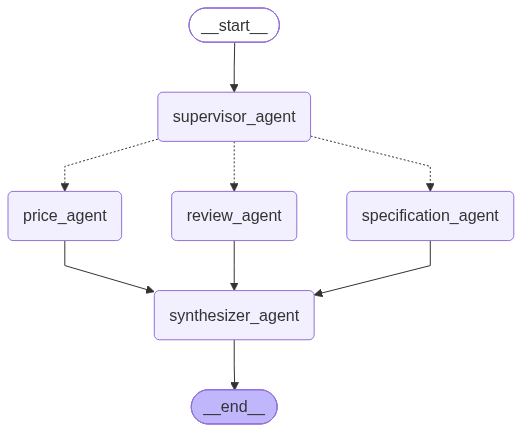

In [15]:
# ============================================================================
# PART 12: Show Chatbot Graph
# ============================================================================

display(Image(graph.get_graph().draw_mermaid_png()))

In [17]:
# ==========================================
# Step 13: Run the Graph
# ==========================================

query = "Should I buy an iPhone 17 or Samsung Galaxy S26? Compare specifications, recent reviews, and price."

result = graph.invoke({
        "user_query": query,
        "messages": []
    })

print(result["final_recommendation"])




inside supervisor_agent --> decision.selected_agents: ['specification_agent', 'review_agent', 'price_agent']





inside route_to_workers --> state[selected_agents]: ['specification_agent', 'review_agent', 'price_agent']




inside price_agent --> price_data: Here are the current prices for the iPhone 17 and Samsung Galaxy S26 across different storage tiers:

**iPhone 17 Prices:**
- **128GB:** $799
- **256GB:** $899
- **512GB:** $1,099

**Samsung Galaxy S26 Prices:**
- **256GB:** $900
- **512GB:** $1,100

In summary, the base model of the iPhone 17 starts at $799 for 128GB, while the Samsung Galaxy S26 starts at $900 for 256GB. The price difference increases with storage capacity, with both devices being similarly priced at the higher storage tiers.




inside specification_agent --> specs_data: **iPhone 17 Specifications:**
- Display: 6.3-inch OLED, 2622 x 1206 resolution
- Processor: A17 Bionic chip
- RAM: 8 GB
- Storage Options: 128 GB, 256 GB, 512 GB, 1 TB
- Rear Cameras: Triple